# HV-010 — Stability & Drift

**Technical gate:** SD-001  
**Dataset release:** VSM-LAB-DATA-v1.1

This notebook evaluates aging-related stability using only analyst-visible stability measurements.

It separates:

- weekly center drift;
- short-term scatter stability;
- monthly pointwise drift;
- span/shape change.

## 1. Engineering Question

> How does DUT error relative to the measured reference evolve with aging time, and is there evidence of center drift, span/shape drift, or degradation of short-term stability?

No external drift acceptance threshold is introduced in this notebook.

## 2. Reproducible Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = Path.cwd()
candidate_roots = [current_dir, *current_dir.parents]

project_root = next(
    (
        path
        for path in candidate_roots
        if (path / "data" / "raw" / "vsm_lab_data_v1_1").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate project root containing "
        "'data/raw/vsm_lab_data_v1_1'."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.stability_analysis import (
    load_frozen_c1_offset,
    load_stability,
    monthly_point_drift,
    summarize_stability_tests,
    weekly_center_drift,
)

tables_dir = project_root / "reports" / "tables"
figures_dir = project_root / "reports" / "figures"
tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")

Project root: /home/runner/work/hvac-sensor-validation-metrology/hvac-sensor-validation-metrology


## 3. SD-01 — Stability Dataset Audit

Expected design:

- 22 Test_IDs;
- 1,320 rows;
- 60 samples/Test_ID;
- 13 weekly center checks at 50 %RH;
- 9 monthly multi-point checks at 30/50/70 %RH;
- all at 25 °C;
- all UP and STABLE.

In [2]:
stability_df, test_matrix_df = load_stability(project_root)

group_sizes = stability_df.groupby("Test_ID").size()

weekly_df = stability_df.loc[
    stability_df["Schedule_Type"].eq("WEEKLY_CENTER_CHECK")
].copy()
monthly_df = stability_df.loc[
    stability_df["Schedule_Type"].eq("MONTHLY_MULTI_POINT")
].copy()

print("Stability dataset audit")
print("-----------------------")
print(f"Rows                  : {len(stability_df)}")
print(f"Test_IDs              : {stability_df['Test_ID'].nunique()}")
print(f"Samples/Test_ID       : {sorted(group_sizes.unique().tolist())}")
print(f"Weekly Test_IDs       : {weekly_df['Test_ID'].nunique()}")
print(f"Monthly Test_IDs      : {monthly_df['Test_ID'].nunique()}")
print(f"Weekly aging days     : {sorted(weekly_df['Aging_Day'].unique().tolist())}")
print(f"Monthly aging days    : {sorted(monthly_df['Aging_Day'].unique().tolist())}")
print(f"Monthly RH setpoints  : {sorted(monthly_df['RH_Setpoint'].unique().tolist())}")

assert len(stability_df) == 1320
assert stability_df["Test_ID"].nunique() == 22
assert sorted(group_sizes.unique().tolist()) == [60]
assert weekly_df["Test_ID"].nunique() == 13
assert monthly_df["Test_ID"].nunique() == 9
assert sorted(weekly_df["Aging_Day"].unique().tolist()) == list(range(0, 85, 7))
assert sorted(monthly_df["Aging_Day"].unique().tolist()) == [30, 60, 90]
assert sorted(monthly_df["RH_Setpoint"].unique().tolist()) == [30.0, 50.0, 70.0]
assert np.allclose(stability_df["Temperature_Setpoint_C"].unique(), [25.0])
assert set(stability_df["Direction"].astype(str).str.upper().unique()) == {"UP"}
assert set(stability_df["Chamber_State"].astype(str).str.upper().unique()) == {"STABLE"}

print("\nSD-01 stability dataset audit: PASS")

Stability dataset audit
-----------------------
Rows                  : 1320
Test_IDs              : 22
Samples/Test_ID       : [60]
Weekly Test_IDs       : 13
Monthly Test_IDs      : 9
Weekly aging days     : [0, 7, 14, 21, 28, 35, 42, 49, 56, 63, 70, 77, 84]
Monthly aging days    : [30, 60, 90]
Monthly RH setpoints  : [30.0, 50.0, 70.0]

SD-01 stability dataset audit: PASS


## 4. SD-02 — Frozen C1 Verification

C1 is loaded unchanged from the HV-006 model artifact.

Because it is a constant additive offset, it shifts absolute bias but cannot alter drift-from-baseline, scatter, or span change.

In [3]:
frozen_c1_offset = load_frozen_c1_offset(project_root)

assert np.isclose(frozen_c1_offset, 1.2266788194444438)

print(f"Frozen C1 offset: {frozen_c1_offset:.10f} %RH")
print("SD-02 frozen C1 verification: PASS")

Frozen C1 offset: 1.2266788194 %RH
SD-02 frozen C1 verification: PASS


## 5. SD-03 — Per-Test_ID Stability Summary

In [4]:
stability_summary_df = summarize_stability_tests(
    stability_df,
    frozen_c1_offset,
)

assert len(stability_summary_df) == 22
assert stability_summary_df["Test_ID"].nunique() == 22

display(
    stability_summary_df[
        [
            "Test_ID",
            "Schedule_Type",
            "Aging_Day",
            "RH_Setpoint",
            "Raw_MBE",
            "C1_MBE",
            "C1_RMSE",
            "Error_SD",
        ]
    ].round(4)
)

print("SD-03 per-Test_ID stability summary: PASS")

,Test_ID,Schedule_Type,Aging_Day,RH_Setpoint,Raw_MBE,C1_MBE,C1_RMSE,Error_SD
0,STAB-014,MONTHLY_MULTI_POINT,30.0,30.0,-1.4602,-0.2335,0.3538,0.2681
1,STAB-015,MONTHLY_MULTI_POINT,30.0,50.0,-1.3523,-0.1257,0.3097,0.2855
2,STAB-016,MONTHLY_MULTI_POINT,30.0,70.0,-1.3530,-0.1263,0.2960,0.2700
3,STAB-017,MONTHLY_MULTI_POINT,60.0,30.0,-1.4493,-0.2227,0.3512,0.2739
4,STAB-018,MONTHLY_MULTI_POINT,60.0,50.0,-1.4592,-0.2325,0.3499,0.2636
5,STAB-019,MONTHLY_MULTI_POINT,60.0,70.0,-1.4930,-0.2663,0.3604,0.2448
6,STAB-020,MONTHLY_MULTI_POINT,90.0,30.0,-1.4115,-0.1848,0.3180,0.2610
7,STAB-021,MONTHLY_MULTI_POINT,90.0,50.0,-1.3247,-0.0980,0.2992,0.2851
8,STAB-022,MONTHLY_MULTI_POINT,90.0,70.0,-1.4555,-0.2288,0.3448,0.2602
9,STAB-001,WEEKLY_CENTER_CHECK,0.0,50.0,-1.5113,-0.2847,0.3807,0.2549


SD-03 per-Test_ID stability summary: PASS


## 6. SD-04 — Weekly Center Drift

Weekly Day 0 is the baseline.

```text
Center_Drift_From_Day0 =
    C1_MBE(day) - C1_MBE(day 0)
```

A descriptive linear trend is fitted over Day 0–84.

In [5]:
weekly_drift_df, weekly_trend_summary_df = weekly_center_drift(
    stability_summary_df
)

display(
    weekly_drift_df[
        [
            "Test_ID",
            "Aging_Day",
            "C1_MBE",
            "Center_Drift_From_Day0",
            "Error_SD",
        ]
    ].round(5)
)

print("Trend summary")
display(weekly_trend_summary_df.round(6))

print("SD-04 weekly center drift: PASS")

,Test_ID,Aging_Day,C1_MBE,Center_Drift_From_Day0,Error_SD
0,STAB-001,0.0,-0.28465,0.00000,0.25487
1,STAB-002,7.0,-0.29782,-0.01317,0.22824
2,STAB-003,14.0,-0.32115,-0.03650,0.25745
3,STAB-004,21.0,-0.25999,0.02467,0.26498
4,STAB-005,28.0,-0.17049,0.11417,0.31514
5,STAB-006,35.0,-0.10899,0.17567,0.25477
6,STAB-007,42.0,-0.18165,0.10300,0.25435
7,STAB-008,49.0,-0.29432,-0.00967,0.25006
8,STAB-009,56.0,-0.12649,0.15817,0.27716
9,STAB-010,63.0,0.21701,0.50167,0.22382


Trend summary


,Metric,Intercept,Slope_per_Day,Slope_per_30_Days,R2,Day84_Value,Max_Abs_Observed
0,Center_Drift_From_Day0,-0.037720,0.004431,0.132932,0.404895,0.047167,0.502500
1,Within_Test_Error_SD,0.258233,-0.000011,-0.000324,0.000139,0.264224,0.315144


SD-04 weekly center drift: PASS


## 7. SD-05 — Monthly Multi-Point Drift and Span Change

Day 30 is the baseline for the monthly campaign.

Pointwise drift is computed separately at 30, 50, and 70 %RH.

Span error:

```text
Span_Error = C1_MBE(70) - C1_MBE(30)
```

Span change is referenced to Day 30.

In [6]:
monthly_point_df, monthly_span_df = monthly_point_drift(
    stability_summary_df
)

print("Monthly point drift")
display(
    monthly_point_df[
        [
            "Test_ID",
            "Aging_Day",
            "RH_Setpoint",
            "C1_MBE",
            "C1_MBE_Day30",
            "Point_Drift_From_Day30",
            "Error_SD",
        ]
    ].round(5)
)

print("Monthly span change")
display(monthly_span_df.round(5))

print("SD-05 monthly point drift/span change: PASS")

Monthly point drift


,Test_ID,Aging_Day,RH_Setpoint,C1_MBE,C1_MBE_Day30,Point_Drift_From_Day30,Error_SD
0,STAB-014,30.0,30.0,-0.23349,-0.23349,0.00000,0.26806
1,STAB-015,30.0,50.0,-0.12565,-0.12565,0.00000,0.28550
2,STAB-016,30.0,70.0,-0.12632,-0.12632,0.00000,0.26997
3,STAB-017,60.0,30.0,-0.22265,-0.23349,0.01083,0.27390
4,STAB-018,60.0,50.0,-0.23249,-0.12565,-0.10683,0.26365
5,STAB-019,60.0,70.0,-0.26632,-0.12632,-0.14000,0.24481
6,STAB-020,90.0,30.0,-0.18482,-0.23349,0.04867,0.26097
7,STAB-021,90.0,50.0,-0.09799,-0.12565,0.02767,0.28508
8,STAB-022,90.0,70.0,-0.22882,-0.12632,-0.10250,0.26017


Monthly span change


,Aging_Day,Span_Error,Span_Change_From_Day30
0,30.0,0.10717,0.00000
1,60.0,-0.04367,-0.15083
2,90.0,-0.04400,-0.15117


SD-05 monthly point drift/span change: PASS


## 8. SD-06 — Weekly / Monthly Center Consistency

The monthly 50 %RH checkpoints are compared against the weekly linear center-drift trend.

This is a consistency diagnostic only; the monthly points are not pooled into the weekly fit.

In [7]:
weekly_center = weekly_drift_df.copy()

trend_row = weekly_trend_summary_df.loc[
    weekly_trend_summary_df["Metric"].eq("Center_Drift_From_Day0")
].iloc[0]

weekly_baseline_c1 = float(
    weekly_center.loc[np.isclose(weekly_center["Aging_Day"], 0.0), "C1_MBE"].iloc[0]
)

monthly_center = monthly_point_df.loc[
    np.isclose(monthly_point_df["RH_Setpoint"], 50.0)
].copy()

monthly_center["Weekly_Predicted_Drift"] = (
    trend_row["Intercept"]
    + trend_row["Slope_per_Day"] * monthly_center["Aging_Day"]
)
monthly_center["Weekly_Predicted_C1_MBE"] = (
    weekly_baseline_c1 + monthly_center["Weekly_Predicted_Drift"]
)
monthly_center["Monthly_Minus_Weekly_Predicted"] = (
    monthly_center["C1_MBE"]
    - monthly_center["Weekly_Predicted_C1_MBE"]
)

display(
    monthly_center[
        [
            "Aging_Day",
            "C1_MBE",
            "Weekly_Predicted_C1_MBE",
            "Monthly_Minus_Weekly_Predicted",
        ]
    ].round(5)
)

print("SD-06 weekly/monthly center consistency diagnostic: PASS")

,Aging_Day,C1_MBE,Weekly_Predicted_C1_MBE,Monthly_Minus_Weekly_Predicted
1,30.0,-0.12565,-0.18944,0.06379
4,60.0,-0.23249,-0.05651,-0.17598
7,90.0,-0.09799,0.07642,-0.17441


SD-06 weekly/monthly center consistency diagnostic: PASS


## 9. Curated Figures

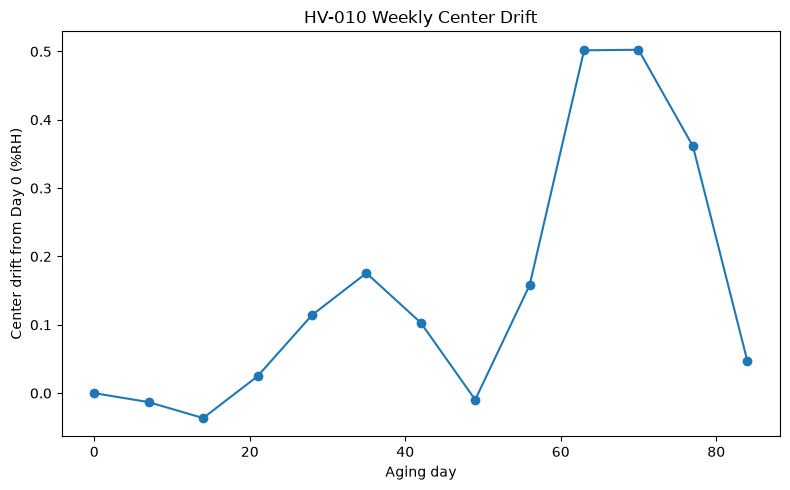

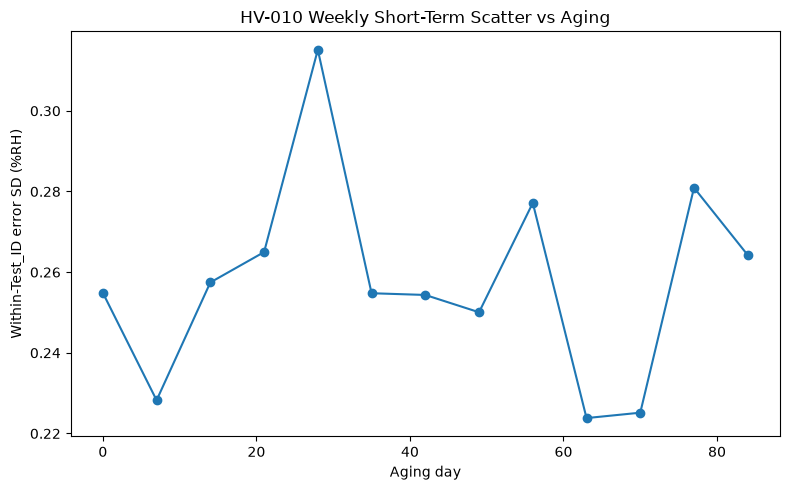

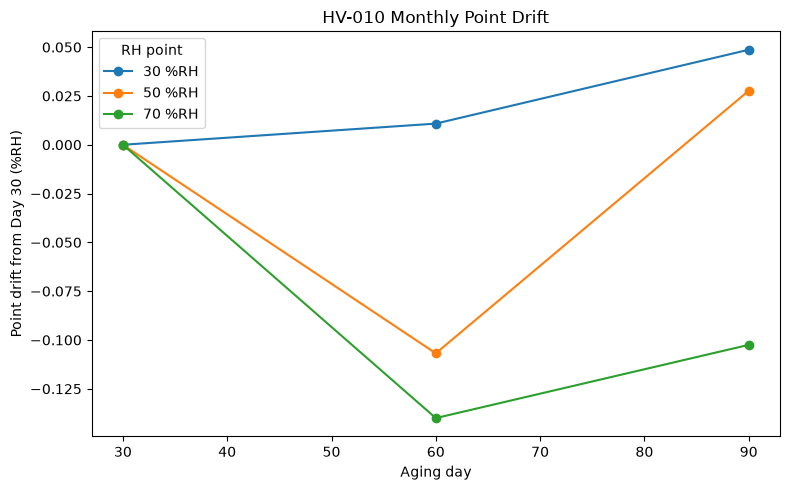

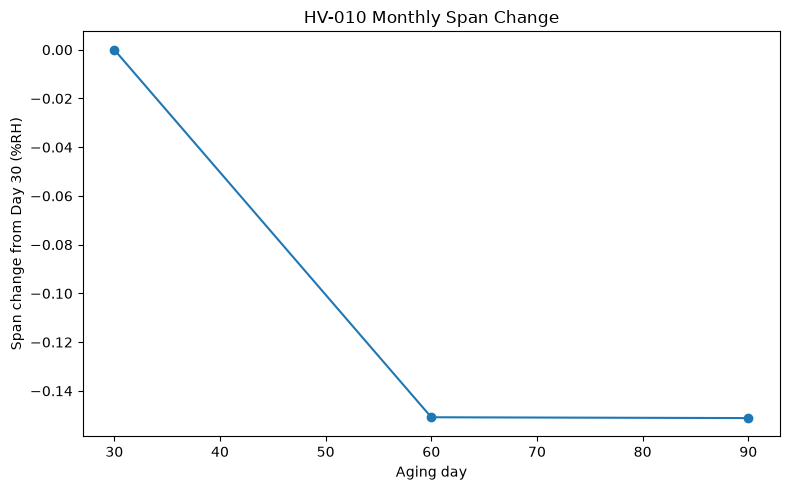

Curated HV-010 figures exported.


In [8]:
# Weekly center drift
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    weekly_drift_df["Aging_Day"],
    weekly_drift_df["Center_Drift_From_Day0"],
    marker="o",
)
ax.set_xlabel("Aging day")
ax.set_ylabel("Center drift from Day 0 (%RH)")
ax.set_title("HV-010 Weekly Center Drift")
fig.tight_layout()
fig.savefig(
    figures_dir / "hv010_weekly_center_drift.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# Weekly scatter vs aging
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    weekly_drift_df["Aging_Day"],
    weekly_drift_df["Error_SD"],
    marker="o",
)
ax.set_xlabel("Aging day")
ax.set_ylabel("Within-Test_ID error SD (%RH)")
ax.set_title("HV-010 Weekly Short-Term Scatter vs Aging")
fig.tight_layout()
fig.savefig(
    figures_dir / "hv010_weekly_scatter_vs_age.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# Monthly point drift
fig, ax = plt.subplots(figsize=(8, 5))
for rh, group in monthly_point_df.groupby("RH_Setpoint"):
    ax.plot(
        group["Aging_Day"],
        group["Point_Drift_From_Day30"],
        marker="o",
        label=f"{rh:.0f} %RH",
    )
ax.set_xlabel("Aging day")
ax.set_ylabel("Point drift from Day 30 (%RH)")
ax.set_title("HV-010 Monthly Point Drift")
ax.legend(title="RH point")
fig.tight_layout()
fig.savefig(
    figures_dir / "hv010_monthly_point_drift.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# Monthly span change
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    monthly_span_df["Aging_Day"],
    monthly_span_df["Span_Change_From_Day30"],
    marker="o",
)
ax.set_xlabel("Aging day")
ax.set_ylabel("Span change from Day 30 (%RH)")
ax.set_title("HV-010 Monthly Span Change")
fig.tight_layout()
fig.savefig(
    figures_dir / "hv010_monthly_span_change.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Curated HV-010 figures exported.")

## 10. Curated Evidence Export

In [9]:
stability_summary_df.to_csv(
    tables_dir / "hv010_stability_test_summary.csv",
    index=False,
)
weekly_drift_df.to_csv(
    tables_dir / "hv010_weekly_center_drift.csv",
    index=False,
)
weekly_trend_summary_df.to_csv(
    tables_dir / "hv010_weekly_trend_summary.csv",
    index=False,
)
monthly_point_df.to_csv(
    tables_dir / "hv010_monthly_point_drift.csv",
    index=False,
)
monthly_span_df.to_csv(
    tables_dir / "hv010_monthly_span_change.csv",
    index=False,
)

print("Curated HV-010 tables exported.")

Curated HV-010 tables exported.


## 11. Initial SD-001 Checkpoint

A clean-kernel Run All should establish:

- SD-01 stability dataset audit PASS;
- SD-02 frozen C1 verification PASS;
- SD-03 per-Test_ID summary PASS;
- SD-04 weekly center drift PASS;
- SD-05 monthly point/span analysis PASS;
- SD-06 weekly/monthly center consistency diagnostic PASS;
- five curated CSV tables;
- four curated figures.

The next step is engineering interpretation, uncertainty-budget handoff, and formal SD-001 gate closure.

## 12. Engineering Interpretation

### 12.1 Weekly center behavior is measurable but not simply monotonic

The weekly Day-0-referenced center drift produces the descriptive linear trend:

```text
Slope           ≈ +0.004431 %RH/day
Slope × 30 days ≈ +0.13293 %RH/30 days
R²              ≈ 0.405
```

However, the actual trajectory is strongly non-monotonic.

Key observations:

```text
Day 0 drift   = 0.0000 %RH
Day 63 drift  ≈ +0.5017 %RH
Day 70 drift  ≈ +0.5025 %RH
Day 84 drift  ≈ +0.0472 %RH
Maximum |drift| ≈ 0.5025 %RH
```

Therefore the positive linear slope should **not** be interpreted as a stable monotonic aging rate.

A more defensible interpretation is:

- measurable medium-term center excursions occur;
- the largest observed center excursion is about 0.50 %RH;
- the response partially returns by Day 84;
- a single linear aging coefficient explains only about 40% of the observed variation.

The observed stability behavior is therefore better represented as time-dependent drift/excursion over the tested interval than as a simple irreversible linear trend.

### 12.2 Short-term scatter does not degrade with aging

Weekly within-Test_ID error SD:

```text
minimum ≈ 0.2238 %RH
median  ≈ 0.2549 %RH
maximum ≈ 0.3151 %RH
Day 84  ≈ 0.2642 %RH
```

The descriptive scatter trend is:

```text
Slope ≈ -0.0000108 %RH/day
R²    ≈ 0.00014
```

This is effectively zero trend.

Therefore there is no evidence that short-term measurement scatter increases materially over the 0–84 day weekly schedule.

This is also consistent with the earlier HV-005 pooled repeatability SD of approximately 0.2593 %RH.

### 12.3 Monthly multi-point campaign shows small common-mode drift but measurable shape/span change

Day-60 point drift relative to Day 30:

```text
30 %RH: +0.0108 %RH
50 %RH: -0.1068 %RH
70 %RH: -0.1400 %RH
Mean  : -0.0787 %RH
```

Day-90 point drift relative to Day 30:

```text
30 %RH: +0.0487 %RH
50 %RH: +0.0277 %RH
70 %RH: -0.1025 %RH
Mean  : -0.0087 %RH
```

The mean/common-mode shift is therefore small by Day 90.

However, the RH-dependent pattern is not negligible.

The calibrated error span is:

```text
Day 30: +0.1072 %RH
Day 60: -0.0437 %RH
Day 90: -0.0440 %RH
```

Therefore:

```text
Span change Day 60 vs Day 30 ≈ -0.1508 %RH
Span change Day 90 vs Day 30 ≈ -0.1512 %RH
```

The nearly identical Day-60 and Day-90 span changes suggest that the shape change appears by Day 60 and then remains approximately stable through Day 90.

This is not removed by C1 because a constant additive offset cancels from span-change calculations.

### 12.4 Weekly and monthly center schedules are not perfectly interchangeable

At 50 %RH, monthly C1 MBE minus the weekly linear-trend prediction is:

```text
Day 30: +0.0638 %RH
Day 60: -0.1760 %RH
Day 90: -0.1744 %RH
```

These differences are modest relative to the larger dynamic errors observed in HV-008/HV-009, but they are not zero.

Because the weekly linear model itself has only moderate explanatory power (R² ≈ 0.405), these residuals should not be interpreted as definitive schedule inconsistency.

Instead, they show that stability behavior contains temporal structure that a single linear trend does not fully capture.

### 12.5 Implications for the uncertainty budget

HV-010 identifies three distinct stability-related quantities that must be handled carefully in HV-011:

1. **Short-term scatter**
   - approximately 0.25–0.32 %RH at individual checkpoints;
   - strongly overlaps conceptually with repeatability evidence from HV-005;
   - should not be double-counted automatically.

2. **Center drift / temporal excursion**
   - maximum observed weekly Day-0-referenced excursion ≈ 0.5025 %RH;
   - systematic/time-dependent behavior;
   - should not automatically be converted into an independent random standard uncertainty.

3. **RH-dependent span/shape change**
   - approximately -0.151 %RH from Day 30 to Day 60/90;
   - represents differential aging behavior across RH;
   - must be distinguished from common-mode center drift.

The uncertainty model must decide whether these effects are corrected, bounded, or represented probabilistically, and must document the dependence assumptions used.

## 13. SD-001 Gate Decision

**SD-001 = PASS WITH DOCUMENTED CONDITIONS**

### Basis for PASS

- all 22 stability Test_IDs and 1,320 rows are structurally valid;
- weekly and monthly schedules match the frozen design;
- frozen C1 is loaded unchanged;
- per-Test_ID bias and scatter are quantified;
- weekly Day-0-referenced drift is quantified;
- short-term scatter stability is assessed;
- monthly pointwise drift and span change are quantified;
- weekly/monthly center behavior is compared without pooling incompatible schedules;
- results are physically coherent and suitable for uncertainty-budget handoff.

### Documented conditions

1. **Non-monotonic center drift:** the weekly center error exhibits excursions up to about 0.50 %RH; a simple linear aging model is inadequate as a complete description.
2. **No scatter degradation:** within-Test_ID scatter shows essentially no aging trend over 0–84 days.
3. **Span/shape change:** monthly error span changes by about -0.151 %RH by Day 60 and remains similar at Day 90.
4. **Schedule dependence:** monthly 50 %RH points do not exactly follow the weekly linear prediction; the weekly linear trend itself has only moderate R².
5. **Uncertainty treatment:** systematic drift and span change must not be blindly converted into independent random uncertainty components.
6. **No external acceptance threshold:** this milestone characterizes stability but does not establish final product compliance.

The next engineering stage is:

```text
HV-011 — Measurement Uncertainty Budget
```